In [36]:
import torch
torch.cuda.is_available()

True

In [37]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


In [38]:
from dataclasses import dataclass
from contextlib import contextmanager, redirect_stdout
from typing import Tuple
import glob
import io
import os
import random
import time

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as Fn
import torchvision.transforms as T
from PIL import Image
from imagecorruptions import corrupt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from torchvision.transforms import functional as F
from torchvision.transforms import InterpolationMode


In [39]:
@dataclass
class Configuration:
    image_size: int = 256
    batch_size_source: int = 16
    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("gaussian_noise",)
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    assignment: str="discrete"
    aug_mode: str = "augment"
    severity: int = 5
CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

### OpenCV transformation for recall improvement

In [40]:

def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image, image_size):
    return F.resize(
        image,
        [image_size, image_size],
        interpolation=T.InterpolationMode.BILINEAR
    )

def center_crop(image, image_size):
    return F.center_crop(image, [image_size, image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def minmax_normalize(tensor, eps=1e-8):
    min_val = tensor.min()
    max_val = tensor.max()
    return (tensor - min_val) / (max_val - min_val + eps)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)

    tensor = convert_to_tensor(image)
    tensor = minmax_normalize(tensor)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)


In [41]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

In [42]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)

In [43]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))

def fast_gaussian_denoise(pil_img, kernel_size=3, sigma=0.8):

    tensor = F.to_tensor(pil_img.convert("RGB"))
    tensor = F.gaussian_blur(
        tensor,
        kernel_size=[kernel_size, kernel_size],
        sigma=[sigma, sigma]
    )
    return F.to_pil_image(tensor.clamp(0, 1))

In [44]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())

In [45]:
class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [46]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)
    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, drop_last=True)
    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    return source_loader, adapt_loader, test_loader

In [47]:
import glob
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from imagecorruptions import corrupt

def apply_corruption(pil_img, name, severity, seed=None):

    if seed is not None:
        np.random.seed(seed)

    arr = np.asarray(pil_img.convert("RGB"))
    corrupted = corrupt(
        arr,
        corruption_name=name,
        severity=severity
    )

    return Image.fromarray(np.asarray(corrupted, dtype=np.uint8))


class SourceDataset(Dataset):
    def __init__(self, CFG, root=None, category=None):
        self.CFG = CFG
        self.root = root if root is not None else CFG.root
        self.category = category if category is not None else CFG.category

        self.paths = sorted(
            glob.glob(
                os.path.join(
                    self.root,
                    self.category,
                    "train",
                    "good",
                    "*.*"
                )
            )
        )

        if len(self.paths) == 0:
            expected_path = os.path.abspath(
                os.path.join(
                    self.root,
                    self.category,
                    "train",
                    "good"
                )
            )

            raise FileNotFoundError(
                "No source images found. Expected images in:\n"
                f"{expected_path}\n\n"
                "Check CFG.root and CFG.category."
            )

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return base_transform(img, self.CFG)


class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.root = root
        self.category = category
        self.CFG = CFG
        self.corruption = corruption

        test_dir = os.path.join(
            root,
            category,
            "test"
        )

        ground_truth_dir = os.path.join(
            root,
            category,
            "ground_truth"
        )

        self.items = []

        if not os.path.isdir(test_dir):
            raise FileNotFoundError(
                f"Test directory does not exist:\n"
                f"{os.path.abspath(test_dir)}"
            )

        for defect in sorted(os.listdir(test_dir)):
            defect_dir = os.path.join(test_dir, defect)

            if not os.path.isdir(defect_dir):
                continue

            image_paths = sorted(
                glob.glob(
                    os.path.join(defect_dir, "*.*")
                )
            )

            for image_path in image_paths:
                if defect == "good":
                    label = 0
                    mask_path = None
                else:
                    label = 1
                    stem = os.path.splitext(
                        os.path.basename(image_path)
                    )[0]

                    mask_path = os.path.join(
                        ground_truth_dir,
                        defect,
                        stem + "_mask.png"
                    )

                self.items.append(
                    (
                        image_path,
                        label,
                        mask_path
                    )
                )

        self.labels = [
            item[1]
            for item in self.items
        ]

        if len(self.items) == 0:
            raise ValueError(
                f"No test images found in:\n"
                f"{os.path.abspath(test_dir)}"
            )

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        image_path, label, mask_path = self.items[idx]

        img = Image.open(image_path).convert("RGB")

        if self.corruption is not None:
            img = apply_corruption(
                img,
                self.corruption,
                self.CFG.severity,
                seed=self.CFG.seed + idx
            )

        x = base_transform(
            img,
            self.CFG
        )

        if (
            mask_path is not None
            and os.path.exists(mask_path)
        ):
            mask = Image.open(mask_path).convert("L")
            m = mask_transform(mask, self.CFG)
        else:
            m = torch.zeros(
                1,
                self.CFG.crop_size,
                self.CFG.crop_size
            )

        return x, label, m

In [48]:
import os
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)
        f3 = self.layer3(f2)

        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)

        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], dim=1)

        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)


@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])


@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]

def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)


model = FeatureExtractor(CFG).to(CFG.device)

source_ds = SourceDataset(CFG, CFG.root, CFG.category)
source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                           num_workers=CFG.num_workers)
memory_bank = build_memory_bank(model, source_loader, CFG)

clean_ds = TestDataset(CFG.root, CFG.category, CFG, corruption=None)
clean_loader = DataLoader(clean_ds, batch_size=CFG.batch_size, shuffle=False,
                          num_workers=CFG.num_workers)
s, y = score_images(model, clean_loader, memory_bank, CFG.device)
print("Clean image AUROC:", roc_auc_score(y, s))

Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


In [49]:
import os
import cv2
import numpy as np
from PIL import Image
from torchvision.transforms import functional as F
from torchvision.transforms import InterpolationMode


CFG.denoiser = "nlm"
CACHE_DIR = "./cache_denoised"
BANK_DIR = "./cache_banks"


def estimate_sigma01(arr01):
    estimates = []
    h, w, _ = arr01.shape
    h2, w2 = (h // 2) * 2, (w // 2) * 2
    for channel in range(3):
        g = arr01[:h2, :w2, channel]
        hh = (g[0::2, 0::2] - g[0::2, 1::2]
              - g[1::2, 0::2] + g[1::2, 1::2]) / 2.0
        estimates.append(np.median(np.abs(hh)) / 0.6745)
    return float(np.mean(estimates))


def denoise_small(pil_img, method):
    pil_img = pil_img.convert("RGB")
    if method == "gauss":
        return fast_gaussian_denoise(pil_img, kernel_size=3, sigma=0.8)

    rgb = np.asarray(pil_img, dtype=np.uint8)
    arr01 = rgb.astype(np.float32) / 255.0
    sigma = estimate_sigma01(arr01)

    if method == "nlm":
        h = float(np.clip(0.8 * sigma * 255.0, 3.0, 40.0))
        bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        out = cv2.fastNlMeansDenoisingColored(bgr, None, h, h, 7, 21)
        return Image.fromarray(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))

    raise ValueError(f"Denoiser must be 'gauss' or 'nlm'; received: {method}")


def cache_path(CFG, category, corruption, image_path):
    defect = os.path.basename(os.path.dirname(image_path))
    stem = os.path.splitext(os.path.basename(image_path))[0]
    tag = (f"{corruption}_sev{CFG.severity}_seed{CFG.seed}_"
           f"resize{CFG.resize_size}_{CFG.denoiser}_v2")
    return os.path.join(CACHE_DIR, category, tag, f"{defect}_{stem}.png")


def process_one(image_path, corruption, severity, seed, method, out_path, size):
    if os.path.exists(out_path):
        return

    np.random.seed(seed)
    with Image.open(image_path) as source:
        arr = np.asarray(source.convert("RGB"))
    arr = np.asarray(corrupt(arr, corruption_name=corruption, severity=severity), dtype=np.uint8)
    img = F.resize(Image.fromarray(arr), [size, size], interpolation=InterpolationMode.BILINEAR)
    img = denoise_small(img, method)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    img.save(out_path)


def warm_cache(category, corruption, CFG, n_jobs=1):

    ds = TestDataset(CFG.root, category, CFG, corruption=None)
    todo = []
    for i, (image_path, _, _) in enumerate(ds.items):
        out = cache_path(CFG, category, corruption, image_path)
        if not os.path.exists(out):
            todo.append((image_path, out, CFG.seed + i))
    for image_path, out, seed in todo:
        process_one(image_path, corruption, CFG.severity, seed,
                    CFG.denoiser, out, CFG.resize_size)
    return len(todo)


def _cached_testdataset_getitem(self, idx):
    image_path, label, mask_path = self.items[idx]
    if self.corruption is None:
        with Image.open(image_path) as im:
            img = im.convert("RGB")
    else:
        out = cache_path(self.CFG, self.category, self.corruption, image_path)
        process_one(image_path, self.corruption, self.CFG.severity,
                    self.CFG.seed + idx, self.CFG.denoiser, out,
                    self.CFG.resize_size)
        with Image.open(out) as im:
            img = im.convert("RGB")
    x = base_transform(img, self.CFG)
    if mask_path is not None and os.path.exists(mask_path):
        with Image.open(mask_path) as mask_img:
            m = mask_transform(mask_img.convert("L"), self.CFG)
    else:
        m = torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
    return x, label, m


TestDataset.__getitem__ = _cached_testdataset_getitem


def get_bank(model, category, CFG, ratio=None, tag="minmax_v2"):

    ratio = CFG.coreset_ratio if ratio is None else float(ratio)
    os.makedirs(BANK_DIR, exist_ok=True)
    path = os.path.join(BANK_DIR, f"{category}_r{ratio:.4f}_{tag}.pt")
    if os.path.exists(path):
        try:
            return torch.load(path, map_location=CFG.device, weights_only=True)
        except TypeError:
            return torch.load(path, map_location=CFG.device)
    with cfg_override(CFG, category=category, coreset_ratio=ratio):
        src = DataLoader(SourceDataset(CFG, CFG.root, category),
                         batch_size=CFG.batch_size, shuffle=False,
                         num_workers=CFG.num_workers)
        bank = build_memory_bank(model, src, CFG)
    torch.save(bank.detach().cpu(), path)
    return bank.to(CFG.device)

In [50]:
def make_test_split(corruption, CFG):

    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    tr, te = split_target(ds, CFG)
    return tr, te
def make_loader(subset, CFG):
    return DataLoader(subset, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}

_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")


for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")

print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.9583
clean             1.0000
gaussian_noise    0.9583
Name: w/o adapt AUROC, dtype: float64


In [52]:
def cost_matrix(z, bank):
    return torch.cdist(z, bank)

def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])

    if z.shape[0] > max_patches:
        indices = torch.randperm(
            z.shape[0],
            device=z.device
        )[:max_patches]

        z = z[indices]

    return z

@torch.no_grad()
def sinkhorn(cost_matrix_value, eps, n_iters):
    N, M = cost_matrix_value.shape
    mean_cost = cost_matrix_value.mean().clamp_min(1e-8)

    normalized_cost = cost_matrix_value / mean_cost
    log_kernel = -normalized_cost / eps

    log_a = -torch.log(
        torch.tensor(
            float(N),
            device=cost_matrix_value.device
        )
    )

    log_b = -torch.log(
        torch.tensor(
            float(M),
            device=cost_matrix_value.device
        )
    )

    log_u = torch.zeros(
        N,
        device=cost_matrix_value.device
    )

    log_v = torch.zeros(
        M,
        device=cost_matrix_value.device
    )

    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(
            log_kernel + log_v.unsqueeze(0),
            dim=1
        )

        log_v = log_b - torch.logsumexp(
            log_kernel + log_u.unsqueeze(1),
            dim=0
        )

    gamma = torch.exp(
        log_kernel
        + log_u.unsqueeze(1)
        + log_v.unsqueeze(0)
    )

    return gamma

@torch.no_grad()
def discretize(gamma):
    N, M = gamma.shape

    pi = torch.zeros(
        N,
        M,
        dtype=torch.bool,
        device=gamma.device
    )

    best_memory_index = gamma.argmax(dim=1)

    pi[
        torch.arange(N, device=gamma.device),
        best_memory_index
    ] = True

    best_target_index = gamma.argmax(dim=0)

    pi[
        best_target_index,
        torch.arange(M, device=gamma.device)
    ] = True

    return pi

def robust_sinkhorn_loss(
    feats,
    bank,
    CFG,
    return_stats=False
):
    z = sample_patches(
        feats,
        CFG.max_adapt_patches
    )

    bank = bank.to(z.device)

    costs = cost_matrix(
        z,
        bank
    )

    gamma = sinkhorn(
        costs.detach(),
        CFG.sinkhorn_eps,
        CFG.sinkhorn_iters
    )

    pi = discretize(gamma)

    normalizer = max(z.shape[0], 1)

    loss = costs[pi].sum() / normalizer

    if return_stats:
        return loss, gamma, pi

    return loss

target_train_subset, _ = make_test_split(
    "gaussian_noise",
    CFG
)

adapt_loader = DataLoader(
    AdaptDataset(target_train_subset),
    batch_size=CFG.adapt_batch_size,
    shuffle=True,
    num_workers=CFG.num_workers
)

batch = next(iter(adapt_loader))

if isinstance(batch, (tuple, list)):
    batch = batch[0]

batch = batch.to(CFG.device)

with torch.no_grad():
    features = model(batch)

loss, gamma, pi = robust_sinkhorn_loss(
    features,
    memory_bank,
    CFG,
    return_stats=True
)

N, M = gamma.shape

print("Loss:", loss.item())
print(
    "Mean row sum:",
    gamma.sum(dim=1).mean().item(),
    "| Expected:",
    1.0 / N
)
print(
    "Mean column sum:",
    gamma.sum(dim=0).mean().item(),
    "| Expected:",
    1.0 / M
)
print(
    "Nonzero assignments:",
    pi.sum().item(),
    "of",
    N * M
)


Loss: 47.90703582763672
Mean row sum: 0.0009765629656612873 | Expected: 0.0009765625
Mean column sum: 3.0514798709191382e-05 | Expected: 3.0514784413048123e-05
Nonzero assignments: 33183 of 33557504


In [53]:
class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]

def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):
                p.requires_grad = True
                bn_params.append(p)
    m.eval()
    return m, bn_params


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=True),
                        batch_size=CFG.adapt_batch_size, shuffle=True,
                        num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history

def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed)
    random.seed(CFG.seed)
    np.random.seed(CFG.seed)


    target_tr, target_te = make_test_split(corruption, CFG)


    target_tr = CachedDataset(target_tr)
    target_te = CachedDataset(target_te)

    model_a, bn_params = make_adapt_model(CFG)

    history = adapt(
        model_a,
        bn_params,
        target_tr,
        memory_bank,
        CFG
    )

    auroc = evaluate(
        model_a,
        make_loader(target_te, CFG),
        memory_bank,
        CFG
    )

    return auroc, history

In [54]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0, 1, 2]

def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    del model_a, bn_params
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return auroc, history


In [55]:
def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    if CFG.assignment == "continuous":
        loss = (gamma * C).sum()
        pi = None
    else:
        pi = discretize(gamma)
        loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=(CFG.aug_mode == "augment")),
                        batch_size=CFG.adapt_batch_size, shuffle=True,
                        num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            if CFG.aug_mode == "copy":
                feats = torch.cat([feats, feats], dim=0)
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
    return history


RUN_ABLATION = False
if RUN_ABLATION:
    ablation_cfgs = {
        "continuous | none": ("continuous", "none"),
        "discrete | none": ("discrete", "none"),
        "discrete | copy": ("discrete", "copy"),
        "discrete | augment": ("discrete", "augment"),
    }
    splits = {}
    for corruption_name in CFG.corruptions:
        tr, te = make_test_split(corruption_name, CFG)
        splits[corruption_name] = (CachedDataset(tr), CachedDataset(te))
    ablation = {}
    for name, (assignment_name, augmentation_name) in ablation_cfgs.items():
        CFG.assignment, CFG.aug_mode = assignment_name, augmentation_name
        for corruption_name in CFG.corruptions:
            tr, te = splits[corruption_name]
            values = []
            for seed_value in SEEDS:
                value, _ = run_roda_seed(tr, te, memory_bank, CFG, seed_value)
                values.append(value)
            ablation[(name, corruption_name)] = float(np.mean(values))
            print(f"{name:22s} {corruption_name:15s} {ablation[(name, corruption_name)]:.4f}")
    CFG.assignment, CFG.aug_mode = "discrete", "augment"
    abl_df = pd.Series(ablation).unstack()
    abl_df.insert(0, "w/o adapt (mean)", np.mean([baseline_results[c] for c in CFG.corruptions]))
    abl_df["mean"] = abl_df[list(CFG.corruptions)].mean(axis=1)
    print(abl_df.round(4))


In [56]:
import io
import time
import random
import pandas as pd
import numpy as np
import torch
from contextlib import redirect_stdout
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score


class CachedDataset(Dataset):

    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        return self.items[idx]


def make_calibrated_split(corruption, CFG, calibration_fraction=0.10):

    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    indices = np.arange(len(ds))
    adapt_idx, remaining_idx = train_test_split(
        indices, train_size=CFG.adapt_ratio, stratify=ds.labels,
        random_state=CFG.seed
    )
    remaining_labels = np.asarray(ds.labels)[remaining_idx]
    cal_idx, test_idx = train_test_split(
        remaining_idx, train_size=calibration_fraction,
        stratify=remaining_labels, random_state=CFG.seed + 1
    )
    return (Subset(ds, adapt_idx.tolist()),
            Subset(ds, cal_idx.tolist()),
            Subset(ds, test_idx.tolist()))


def calibrated_recall(model, calibration_subset, test_subset, bank, CFG, fpr):
    cal_scores, cal_labels = score_images(
        model, make_loader(calibration_subset, CFG), bank, CFG.device
    )
    normal_cal_scores = cal_scores[cal_labels == 0]
    if len(normal_cal_scores) == 0:
        raise ValueError("Calibration split contains no normal images; cannot set FPR threshold.")
    threshold = get_threshold_at_fpr(normal_cal_scores, fpr)
    test_scores, test_labels = score_images(
        model, make_loader(test_subset, CFG), bank, CFG.device
    )
    recall, tp, fn = compute_recall(test_scores, test_labels, threshold)
    return (roc_auc_score(test_labels, test_scores), recall, threshold,
            test_scores, test_labels, tp, fn)


def run_denoise_study(categories, seeds=(0,), fpr=0.075,
                      corruption="gaussian_noise", do_adapt=True,
                      out_csv="denoise_study.csv", calibration_fraction=0.10):
    rows = []
    for cat in categories:
        t0 = time.time()
        with cfg_override(CFG, category=cat):
            bank = get_bank(model, cat, CFG, ratio=CFG.coreset_ratio)
            warm_cache(cat, corruption, CFG)
            tr, cal, te = make_calibrated_split(
                corruption, CFG, calibration_fraction=calibration_fraction
            )
            tr, cal, te = CachedDataset(tr), CachedDataset(cal), CachedDataset(te)

            auc_before, rec_before, thr_before, *_ = calibrated_recall(
                model, cal, te, bank, CFG, fpr
            )
            row = dict(category=cat, denoiser=CFG.denoiser, fpr=fpr,
                       coreset_ratio=CFG.coreset_ratio,
                       auroc_before=auc_before, recall_before=rec_before,
                       threshold_before=thr_before)

            if do_adapt:
                a_auc, a_rec, a_thr = [], [], []
                for sd in seeds:
                    torch.manual_seed(sd)
                    random.seed(sd)
                    np.random.seed(sd)
                    m, bn = make_adapt_model(CFG)
                    with redirect_stdout(io.StringIO()):
                        adapt(m, bn, tr, bank, CFG)
                    auc_after, rec_after, threshold_after, *_ = calibrated_recall(
                        m, cal, te, bank, CFG, fpr
                    )
                    a_auc.append(auc_after)
                    a_rec.append(rec_after)
                    a_thr.append(threshold_after)
                    del m, bn
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                row.update(auroc_after=float(np.mean(a_auc)),
                           auroc_after_std=float(np.std(a_auc)),
                           recall_after=float(np.mean(a_rec)),
                           recall_after_std=float(np.std(a_rec)),
                           threshold_after=float(np.mean(a_thr)))

        row["minutes"] = (time.time() - t0) / 60.0
        rows.append(row)
        print({k: (round(v, 4) if isinstance(v, (float, np.floating)) else v)
               for k, v in row.items()})
        pd.DataFrame(rows).to_csv(out_csv, index=False)
    return pd.DataFrame(rows)

In [57]:
import numpy as np

def get_threshold_at_fpr(normal_scores, target_fpr=0.05):

    normal_scores = np.asarray(normal_scores, dtype=float).reshape(-1)
    normal_scores = normal_scores[np.isfinite(normal_scores)]
    if normal_scores.size == 0:
        raise ValueError("normal_scores is empty; threshold cannot be calibrated.")
    if not 0.0 < target_fpr < 1.0:
        raise ValueError("target_fpr must be between 0 and 1.")

    try:
        return float(np.quantile(normal_scores, 1.0 - target_fpr, method="higher"))
    except TypeError:
        return float(np.quantile(normal_scores, 1.0 - target_fpr, interpolation="higher"))


def compute_recall(scores, labels, threshold):
    scores = np.asarray(scores).reshape(-1)
    labels = np.asarray(labels).reshape(-1).astype(int)
    preds = (scores >= threshold).astype(int)
    tp = int(np.sum((preds == 1) & (labels == 1)))
    fn = int(np.sum((preds == 0) & (labels == 1)))
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    return recall, tp, fn

In [58]:
def run_roda_seed_with_recall(target_tr, calibration_subset, target_te,
                              memory_bank, CFG, seed, target_fpr=0.075):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    result = calibrated_recall(model_a, calibration_subset, target_te,
                               memory_bank, CFG, target_fpr)
    del model_a, bn_params
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, history

Gaussian-noise categories (13): ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']

Denoiser: Gaussian smoothing
  bottle       AUROC 0.922 -> 0.882; recall 0.891 -> 0.978
Source patches: 175616, memory bank size N_M: 35123
  cable        AUROC 0.935 -> 0.973; recall 0.896 -> 0.940
  capsule      AUROC 0.547 -> 0.699; recall 0.688 -> 0.725
Source patches: 219520, memory bank size N_M: 43904
  carpet       AUROC 0.928 -> 0.941; recall 0.815 -> 0.908
  grid         AUROC 0.624 -> 0.771; recall 0.690 -> 0.548
Source patches: 306544, memory bank size N_M: 61308
  hazelnut     AUROC 0.945 -> 0.966; recall 0.961 -> 0.922
Source patches: 192080, memory bank size N_M: 38416
  leather      AUROC 0.999 -> 0.997; recall 1.000 -> 0.985
  metal_nut    AUROC 0.680 -> 0.635; recall 0.627 -> 0.517
Source patches: 180320, memory bank size N_M: 36064
  tile         AUROC 0.992 -> 0.980; recall 0.951 -> 1.000
  toothb

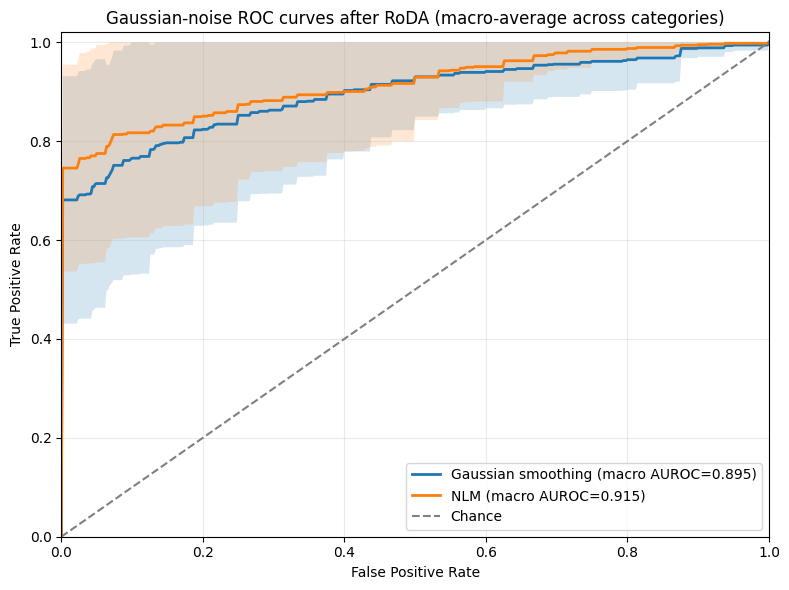

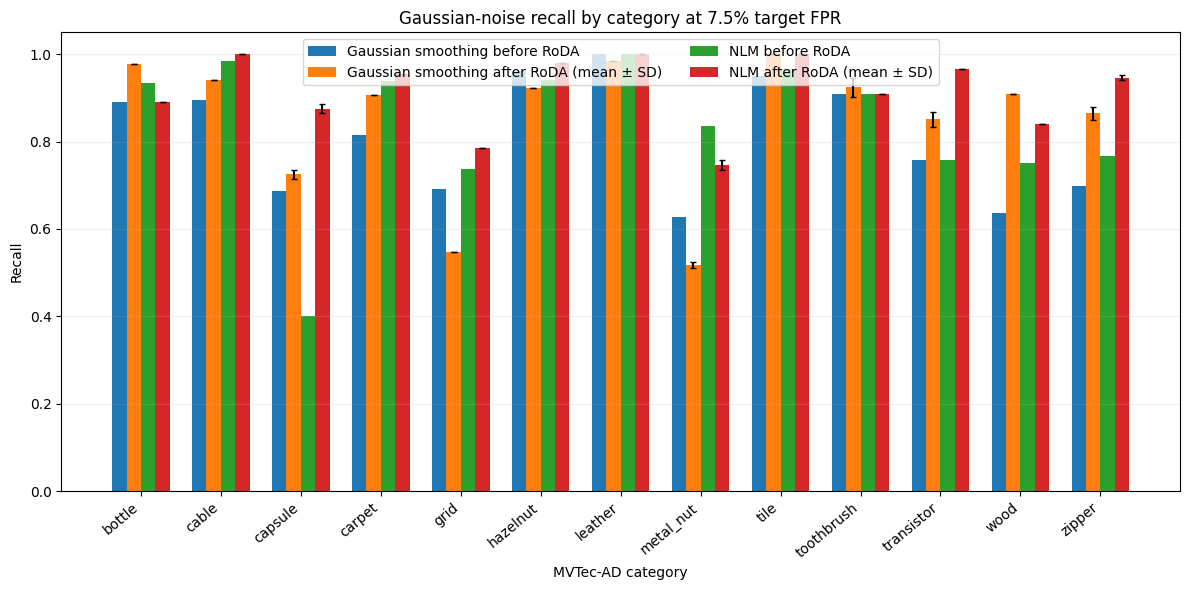

In [60]:
import os
import io
import random
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
from sklearn.metrics import auc, roc_curve, roc_auc_score

CORRUPTION = "gaussian_noise"
DENOISERS = ["gauss", "nlm"]
METHOD_LABELS = {"gauss": "Gaussian smoothing", "nlm": "NLM"}
SEEDS = [0, 1, 2]
TARGET_FPR = 0.075
ROC_FPR_GRID = np.linspace(0.0, 1.0, 501)

CATEGORIES = sorted(
    name for name in os.listdir(CFG.root)
    if os.path.isdir(os.path.join(CFG.root, name, "train", "good"))
    and os.path.isdir(os.path.join(CFG.root, name, "test"))
)
if not CATEGORIES:
    raise FileNotFoundError(f"No MVTec-AD categories found under {os.path.abspath(CFG.root)}")
print(f"Gaussian-noise categories ({len(CATEGORIES)}): {CATEGORIES}")

all_rows = []
roc_tprs = {method: [] for method in DENOISERS}
base_model = FeatureExtractor(CFG).to(CFG.device)

for method in DENOISERS:
    CFG.denoiser = method
    print(f"\nDenoiser: {METHOD_LABELS[method]}")
    for category in CATEGORIES:
        with cfg_override(CFG, category=category):
            bank = get_bank(base_model, category, CFG, ratio=CFG.coreset_ratio)
            warm_cache(category, CORRUPTION, CFG)
            tr, cal, te = make_calibrated_split(CORRUPTION, CFG, calibration_fraction=0.10)
            tr, cal, te = CachedDataset(tr), CachedDataset(cal), CachedDataset(te)

            auc_before, recall_before, _, _, labels, _, _ = calibrated_recall(
                base_model, cal, te, bank, CFG, TARGET_FPR
            )
            after_aucs, after_recalls, score_runs = [], [], []
            for seed in SEEDS:
                torch.manual_seed(seed)
                random.seed(seed)
                np.random.seed(seed)
                with redirect_stdout(io.StringIO()):
                    result, _ = run_roda_seed_with_recall(
                        tr, cal, te, bank, CFG, seed, TARGET_FPR
                    )
                auc_after, recall_after, _, scores, labels_after, _, _ = result
                after_aucs.append(auc_after)
                after_recalls.append(recall_after)
                score_runs.append(scores)

            mean_scores = np.mean(np.stack(score_runs), axis=0)
            fpr, tpr, _ = roc_curve(labels_after, mean_scores)
            interp_tpr = np.interp(ROC_FPR_GRID, fpr, tpr)
            interp_tpr[0] = 0.0
            roc_tprs[method].append(interp_tpr)
            all_rows.append({
                "category": category,
                "corruption": CORRUPTION,
                "severity": CFG.severity,
                "denoiser": method,
                "target_fpr": TARGET_FPR,
                "auroc_before_roda": auc_before,
                "auroc_after_roda_mean": float(np.mean(after_aucs)),
                "auroc_after_roda_std": float(np.std(after_aucs)),
                "recall_before_roda": recall_before,
                "recall_after_roda_mean": float(np.mean(after_recalls)),
                "recall_after_roda_std": float(np.std(after_recalls)),
                "seeds": len(SEEDS),
            })
            print(f"  {category:12s} AUROC {auc_before:.3f} -> {np.mean(after_aucs):.3f}; "
                  f"recall {recall_before:.3f} -> {np.mean(after_recalls):.3f}")
            del bank, tr, cal, te
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

results_df = pd.DataFrame(all_rows)
results_df.to_csv("gaussian_noise_denoise_all_categories.csv", index=False)
print("Saved category results to gaussian_noise_denoise_all_categories.csv")


fig, ax = plt.subplots(figsize=(8, 6))
for method in DENOISERS:
    curves = np.asarray(roc_tprs[method])
    mean_tpr = curves.mean(axis=0)
    std_tpr = curves.std(axis=0)
    mean_tpr[-1] = 1.0
    ax.plot(ROC_FPR_GRID, mean_tpr, linewidth=2,
            label=f"{METHOD_LABELS[method]} (macro AUROC={auc(ROC_FPR_GRID, mean_tpr):.3f})")
    ax.fill_between(ROC_FPR_GRID, np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1), alpha=0.18)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False Positive Rate", ylabel="True Positive Rate",
       title="Gaussian-noise ROC curves after RoDA (macro-average across categories)")
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


plot_df = results_df.pivot(index="category", columns="denoiser",
                           values=["recall_before_roda", "recall_after_roda_mean", "recall_after_roda_std"])
x = np.arange(len(plot_df))
width = 0.18
fig, ax = plt.subplots(figsize=(max(12, len(plot_df) * 0.8), 6))
for j, method in enumerate(DENOISERS):
    offset = (j - 0.5) * 2 * width
    ax.bar(x + offset - width/2, plot_df[("recall_before_roda", method)], width,
           label=f"{METHOD_LABELS[method]} before RoDA")
    ax.bar(x + offset + width/2, plot_df[("recall_after_roda_mean", method)], width,
           yerr=plot_df[("recall_after_roda_std", method)], capsize=2,
           label=f"{METHOD_LABELS[method]} after RoDA (mean ± SD)")
ax.set_xticks(x, plot_df.index, rotation=40, ha="right")
ax.set_ylim(0, 1.05)
ax.set_xlabel("MVTec-AD category")
ax.set_ylabel("Recall")
ax.set_title("Gaussian-noise recall by category at 7.5% target FPR")
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


## Final experiment run order

1. Set `CFG.root` to the MVTec-AD dataset directory and confirm category folders contain `train/good` and `test`.
2. Restart the kernel and run cells from top to bottom.
3. Run the final experiment cell to compare **Gaussian smoothing** and **NLM** on **Gaussian noise at severity 5** across all detected categories.
4. The AUROC figure plots false-positive rate against true-positive rate and shows macro-average ROC curves across categories after RoDA. The recall figure compares before and after RoDA at a target FPR of 7.5%; error bars show standard deviation across three adaptation seeds.
5. Category-level metric values are saved to `Results/gaussian_noise_denoise_all_categories.csv`.

Only Gaussian smoothing and NLM are compared in this final evaluation. The final experiment uses held-out normal calibration images for the recall threshold and a separate final test split.
